# Бейзлайн: расстояние до среднего окна

Ноутбук показывает, как подключить свою модель к `industrial_novelty`.
Метод намеренно простой: нормальное окно запоминается как одна средняя точка,
а оценка новизны — евклидово расстояние до неё. Чем дальше окно, тем выше оценка.

Для следующей модели достаточно заменить класс ниже. Окна, порог и таблица по неисправностям остаются теми же.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from industrial_novelty import (
    ExperimentConfig,
    NoveltyDetector,
    build_experiment,
    evaluate_model,
)

## Окна

Обучение и валидация берутся из нормальных обучающих прогонов и не делят один `simulationRun`.
Порог потом выбирается по валидации, а ложные срабатывания считаются на нормальном тесте.
`channels="xmeas"` оставляет 41 измеряемый параметр. Управляющие клапаны подключаются через `"all"` или `"xmv"`.

In [2]:
experiment = build_experiment(
    ExperimentConfig(
        window_size=50,
        stride=50,
        channels="xmeas",
    )
)
experiment.counts()

,split,n_windows,n_runs,window_size,n_channels
0,train,4000,400,50,41
1,val,1000,100,50,41
2,normal_test,9500,500,50,41


## Модель

Наследник реализует два метода. `fit` и `score` уже проверяют форму массива, их не переопределяют.

`X` имеет форму `(число окон, длина окна, число каналов)`. В обучение попадают только нормальные окна.

In [3]:
class MeanWindowDistance(NoveltyDetector):
    """Расстояние до среднего нормального окна."""

    def fit_windows(self, X: np.ndarray) -> None:
        flat = X.reshape(len(X), -1).astype(np.float64, copy=False)
        self.center_ = flat.mean(axis=0)

    def anomaly_score(self, X: np.ndarray) -> np.ndarray:
        flat = X.reshape(len(X), -1).astype(np.float64, copy=False)
        return np.linalg.norm(flat - self.center_, axis=1)


model = MeanWindowDistance().fit(experiment.train.X)
model.center_.shape

(2050,)

## Оценки одного прогона

`score` возвращает массив той же длины, что и `batch.X`. `with_scores` приклеивает его к паспорту окна:
номер неисправности, прогон, границы отсчётов, метка и флаг аварийного останова.
У неисправности 4 отказ начинается с 161-го отсчёта, останов по давлению не ожидается.
Окна 1–150 помечены как норма, следующее сохранённое окно начинается с 201: окно 151–200 пересекает 160-й отсчёт и отброшено.


In [4]:
fault_4 = experiment.faulty_test(4)
scored_4 = fault_4.batch.with_scores(model.score(fault_4.batch.X))
scored_4.loc[scored_4["simulation_run"] == fault_4.simulation_runs[0]].head(8)

,fault_number,simulation_run,sample_start,sample_end,label,post_shutdown,split,score
0,4,1,1,50,0,False,faulty_test,41.929609
1,4,1,51,100,0,False,faulty_test,48.220781
2,4,1,101,150,0,False,faulty_test,49.806636
3,4,1,201,250,1,False,faulty_test,44.224944
4,4,1,251,300,1,False,faulty_test,49.861283
5,4,1,301,350,1,False,faulty_test,53.645016
6,4,1,351,400,1,False,faulty_test,48.416713
7,4,1,401,450,1,False,faulty_test,39.646553


## Общая оценка

`evaluate_model` ставит порог так, чтобы на валидации доля окон с оценкой не ниже порога не превышала `target_fpr`.
Обнаружение считается только по окнам отказа до аварийного останова. Задержка измеряется в отсчётах от 160-го до конца первого сработавшего окна.

Рядом с оконным FPR печатается доля нормальных прогонов, в которых было хотя бы одно такое окно.
В таблице по неисправностям `early_detection_rate` — доля прогонов, пойманных на первом допустимом окне,
`median_alarm_persistence` — медиана доли тревожных окон на участке отказа,
`median_shutdown_margin_minutes` — медиана минут от первого срабатывания до начала плато,
`auroc` — насколько окна этого отказа до останова выше нормального теста.

In [5]:
report = evaluate_model(model, experiment, target_fpr=0.01)
print(
    f"порог {report.threshold:.3f}, "
    f"FPR окон {report.normal_test_fpr:.3f}, "
    f"доля нормальных прогонов с тревогой {report.false_alarm_run_rate:.3f}"
)
report.per_fault

порог 58.743, FPR окон 0.019, доля нормальных прогонов с тревогой 0.234


,fault_number,n_runs,n_scoreable,n_detected,detection_rate,early_detection_rate,median_alarm_persistence,median_delay_samples,median_delay_minutes,median_shutdown_margin_minutes,n_shutdown_runs,n_unscoreable,auroc
0,1,500,500,500,1.000,1.000,1.000000,90.0,270.0,NaN,0,0,1.000000
1,2,500,500,500,1.000,1.000,1.000000,90.0,270.0,NaN,0,0,1.000000
2,3,500,500,109,0.218,0.028,0.000000,390.0,1170.0,NaN,0,0,0.537282
3,4,500,500,105,0.210,0.024,0.000000,390.0,1170.0,NaN,0,0,0.524176
4,5,500,500,500,1.000,1.000,0.200000,90.0,270.0,NaN,0,0,0.665748
5,6,500,500,500,1.000,1.000,1.000000,90.0,270.0,153.0,500,0,1.000000
6,7,500,500,500,1.000,1.000,0.400000,90.0,270.0,NaN,0,0,0.751477
7,8,500,500,500,1.000,1.000,1.000000,90.0,270.0,NaN,0,0,0.999997
8,9,500,500,121,0.242,0.026,0.000000,390.0,1170.0,NaN,0,0,0.547143
9,10,500,500,500,1.000,0.112,0.466667,190.0,570.0,NaN,0,0,0.918770


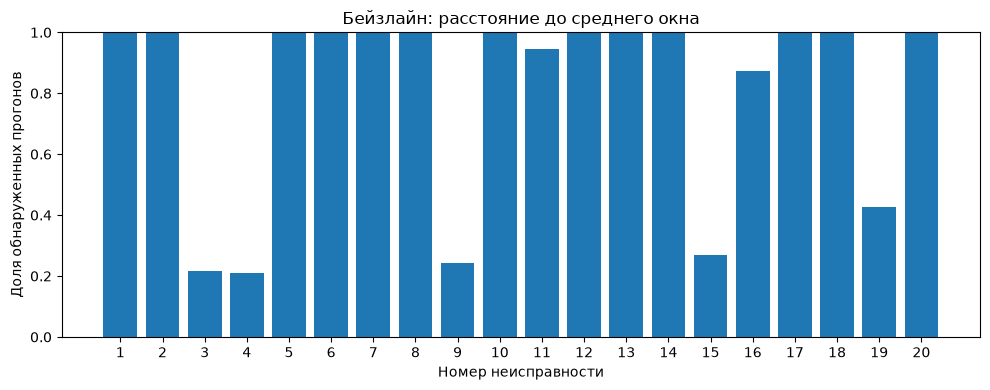

In [6]:
table = report.per_fault

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(table["fault_number"], table["detection_rate"])
ax.set_xlabel("Номер неисправности")
ax.set_ylabel("Доля обнаруженных прогонов")
ax.set_ylim(0, 1)
ax.set_xticks(table["fault_number"])
ax.set_title("Бейзлайн: расстояние до среднего окна")
plt.tight_layout()
plt.show()